In [16]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib
from joblib import Parallel, delayed
import time

class GaTabuScheduler:
    """使用遺傳算法與禁忌搜索的混合排程器 (加速版：將資料轉成快取結構)"""
    
    def __init__(self, data_file="data.xlsx", seed=42):
        """初始化排程器，讀取資料並設定預設參數，同時預處理數據以提升效能"""
        # 設定中文字型避免中文亂碼
        matplotlib.rcParams['font.sans-serif'] = ['Microsoft JhengHei','SimHei','Arial Unicode MS']
        matplotlib.rcParams['axes.unicode_minus'] = False
        
        # 設定隨機種子
        random.seed(seed)
        np.random.seed(seed)
        
        # 讀取資料（只讀一次，後續改用內存中的 dictionary）
        self.df_cart = pd.read_excel(data_file, sheet_name="CART")
        self.df_wip  = pd.read_excel(data_file, sheet_name="WIP")
        self.df_xfer = pd.read_excel(data_file, sheet_name="XFER_TIME")
        
        # 將 CART 與 WIP 資料轉成 dictionary 以加速查詢
        # carts: {CART_ID: {"INIT_LOC": ... 等}}
        self.carts = {row["CART_ID"]: row for _, row in self.df_cart.iterrows()}
        
        # wips: {WIP_ID: {"FROM": ..., "TO": ..., "Remaining Q-Time": ...}}
        self.wips = {row["WIP_ID"]: row for _, row in self.df_wip.iterrows()}
        
        # 建立 XFER_TIME 快速查表（同原來方式）
        self.xfer_dict = {}
        for _, row in self.df_xfer.iterrows():
            frm = row["FROM"]
            to = row["TO"]
            if frm not in self.xfer_dict:
                self.xfer_dict[frm] = {}
            self.xfer_dict[frm][to] = row["XFER_TIME"]
        
        # 遺傳演算法參數
        self.pop_size = 50         # 族群大小
        self.generations = 500     # 進化世代數
        self.elite_size = 10       # 精英保留數
        self.mutation_rate = 0.4   # 突變率
        self.tournament_size = 10  # 錦標賽選擇樣本數
        self.batch_capacity = 2    # 每台 CART 一次最多接受的訂單數
        self.earlier_ga_stop = 20  # 連續多少代無改善就提前終止
        
        # 禁忌搜索參數
        self.tabu_iterations = 5   # 禁忌搜索迭代次數
        self.tabu_tenure = 10      # 禁忌期限
        self.tabu_frequency = 5    # 每幾代GA使用一次禁忌搜索
        self.tabu_elite_ratio = 0.02  # 應用禁忌搜索的精英比例
        self.earlier_ts_stop = 20  # 連續多少代無改善就提前終止
        self.rep = 2              # 鄰域生成數
        
        # 初始化結果變數
        self.best_solution = None
        self.best_fit = float('inf')
        self.best_details = None
        self.best_metrics = None
        self.evolution_history = {"best": [], "avg": []}
        self.execution_time = 0
    
    def repair_chromosome(self, chromosome):
        """修正函式：確保每台 CART 的訂單數不超過容量，且每個訂單只排入一次"""
        assigned = set()
        for cart in chromosome:
            new_list = []
            for w in chromosome[cart]:
                if w not in assigned and len(new_list) < self.batch_capacity:
                    new_list.append(w)
                    assigned.add(w)
            chromosome[cart] = new_list
        
        global_orders = set(self.df_wip["WIP_ID"].tolist())
        missing = list(global_orders - assigned)
        random.shuffle(missing)
        
        for order in missing:
            added = False
            for cart in chromosome:
                if len(chromosome[cart]) < self.batch_capacity:
                    chromosome[cart].append(order)
                    assigned.add(order)
                    added = True
                    break
            if not added:
                cart = random.choice(list(chromosome.keys()))
                idx = random.randrange(len(chromosome[cart]))
                chromosome[cart][idx] = order
                assigned.add(order)
        
        return chromosome
    
    def init_population(self, pop_size):
        """基因初始族群產生：每台 CART 挑選訂單後隨機排列產生初始解"""
        population = []
        wip_ids = self.df_wip["WIP_ID"].tolist()
        random.shuffle(wip_ids)
        cart_ids = self.df_cart["CART_ID"].tolist()
        
        base_assignment = {cart: [] for cart in cart_ids}
        for w in wip_ids:
            available = [c for c in cart_ids if len(base_assignment[c]) < self.batch_capacity]
            if available:
                chosen = random.choice(available)
                base_assignment[chosen].append(w)
        
        for _ in range(pop_size):
            chromosome = {}
            for cart in cart_ids:
                orders = base_assignment[cart].copy()
                random.shuffle(orders)
                chromosome[cart] = orders
            population.append(chromosome)
        
        return population
    
    def generate_mixed_sequence(self, wip_list):
        """
        生成最佳操作序列（pickup 和 delivery 混合排序）：
        採用貪心法，從當前位置出發，每次在所有可執行的操作中選取距離最近的，
        其中可執行操作包含：
        - 尚未 pickup 的訂單 (pickup)
        - 已 pickup 但尚未 delivery 的訂單 (delivery)
        """
        if not wip_list:
            return []
        
        # 使用第一個 xfer_dict 的起始地作為初始位置
        start_loc = list(self.xfer_dict.keys())[0]
        current_loc = start_loc
        
        # 初始化：所有訂單待 pickup，待 delivery清單為空
        pending_pickups = wip_list.copy()
        pending_deliveries = []
        sequence = []
        
        while pending_pickups or pending_deliveries:
            candidates = []
            # 從待 pickup 中選取：計算從當前位置到每個訂單 pickup 地點的距離
            for w in pending_pickups:
                pickup_loc = self.wips[w]["FROM"]
                d = self.xfer_dict[current_loc].get(pickup_loc, float('inf'))
                candidates.append(("pickup", w, d, pickup_loc))
            # 從待 delivery 中選取：計算從當前位置到每個訂單 delivery 地點的距離
            for w in pending_deliveries:
                delivery_loc = self.wips[w]["TO"]
                d = self.xfer_dict[current_loc].get(delivery_loc, float('inf'))
                candidates.append(("delivery", w, d, delivery_loc))
            if not candidates:
                break
            # 選擇額外距離最低的操作
            op, w, _, next_loc = min(candidates, key=lambda x: x[2])
            sequence.append((op, w))
            current_loc = next_loc
            if op == "pickup":
                pending_pickups.remove(w)
                pending_deliveries.append(w)
            else:
                pending_deliveries.remove(w)
        
        return sequence
    
    def evaluate_cart(self, cart, wip_list):
        """評估單台 CART 的運作：根據操作序列計算超時訂單數和總行駛距離，
           利用預先處理的 self.carts 與 self.wips 提升查詢速度"""
        init_loc = self.carts[cart]["INIT_LOC"]
        current_loc = init_loc
        time_elapsed = 0
        distance = 0
        schedule = []
        rejections = 0
        
        if len(wip_list) == 0:
            return 0, 0, 0, []
        
        ops = self.generate_mixed_sequence(wip_list)
        for op, wip in ops:
            info = self.wips[wip]
            if op == "pickup":
                loc = info["FROM"]
                d = self.xfer_dict[current_loc][loc]
                distance += d
                time_elapsed += d
                schedule.append({'wip_id': wip, 'action': 'PICKUP', 'location': loc, 'time': time_elapsed})
                current_loc = loc
            else:
                loc = info["TO"]
                d = self.xfer_dict[current_loc][loc]
                distance += d
                time_elapsed += d
                schedule.append({'wip_id': wip, 'action': 'DELIVERY', 'location': loc, 'time': time_elapsed})
                if time_elapsed > info["Remaining Q-Time"]:
                    rejections += 1
                current_loc = loc
        
        return rejections, distance, time_elapsed, schedule
    
    def fitness(self, chromosome):
        """計算整體染色體的適應值，同時回傳各 CART 的詳細排程與指標"""
        total_rejections = 0
        total_distance = 0
        max_completion_time = 0
        cart_details = {}
        cart_metrics = {}
        for cart, orders in chromosome.items():
            orders = orders[:self.batch_capacity]
            rej, dist, finish_time, sched = self.evaluate_cart(cart, orders)
            total_rejections += rej
            total_distance += dist
            max_completion_time = max(max_completion_time, finish_time)
            cart_details[cart] = sched
            cart_metrics[cart] = {"rejections": rej, "distance": dist, "completion_time": finish_time}
        fit_val = total_rejections * 10000 + total_distance
        return fit_val, cart_details, cart_metrics
    
    def crossover(self, p1, p2):
        """交配：對兩個父代染色體採取 CART 分半交配後修正"""
        child = {}
        cart_ids = list(p1.keys())
        random.shuffle(cart_ids)
        half = len(cart_ids) // 2
        assigned = set()
        for cart in cart_ids[:half]:
            child[cart] = p1[cart].copy()
            assigned.update(p1[cart])
        for cart in cart_ids[half:]:
            lst = [w for w in p2[cart] if w not in assigned]
            child[cart] = lst
            assigned.update(lst)
        child = self.repair_chromosome(child)
        return child
    
    def mutate(self, chromosome):
        """突變：隨機從兩台 CART 中交換一筆訂單"""
        if random.random() > self.mutation_rate:
            return chromosome
        mutated = {c: v.copy() for c, v in chromosome.items()}
        carts_list = list(mutated.keys())
        c1, c2 = random.sample(carts_list, 2)
        if mutated[c1] and mutated[c2]:
            i = random.randrange(len(mutated[c1]))
            j = random.randrange(len(mutated[c2]))
            mutated[c1][i], mutated[c2][j] = mutated[c2][j], mutated[c1][i]
        mutated = self.repair_chromosome(mutated)
        return mutated
    
    def tournament_selection(self, population, fitness_details):
        """錦標賽選擇"""
        selected = random.sample(range(len(population)), self.tournament_size)
        best = min(selected, key=lambda i: fitness_details[i][0])
        return population[best]
    
    def shake_solution(self, solution):
        """解的大變動操作，用於跳出局部最佳"""
        shaken = {c: v.copy() for c, v in solution.items()}
        carts = list(shaken.keys())
        chosen_carts = random.sample(carts, min(len(carts) // 3 + 1, len(carts)))
        all_orders = []
        for cart in chosen_carts:
            all_orders.extend(shaken[cart])
            shaken[cart] = []
        random.shuffle(all_orders)
        for order in all_orders:
            cart = random.choice(chosen_carts)
            if len(shaken[cart]) < self.batch_capacity:
                shaken[cart].append(order)
            else:
                available = [c for c in chosen_carts if len(shaken[c]) < self.batch_capacity]
                if available:
                    shaken[random.choice(available)].append(order)
                else:
                    cart = random.choice(chosen_carts)
                    idx = random.randrange(len(shaken[cart]))
                    shaken[cart][idx] = order
        return self.repair_chromosome(shaken)
    
    def generate_neighbors(self, current_solution):
        """產生大量鄰域候選解"""
        neighbors = []
        rep = self.rep
        carts = list(current_solution.keys())
        # 跨 CART 交換
        for _ in range(rep):
            cart_pairs = random.sample([(i, j) for i in range(len(carts)) for j in range(i+1, len(carts))],
                                        min(5, len(carts)*(len(carts)-1)//2))
            for i, j in cart_pairs:
                cart1, cart2 = carts[i], carts[j]
                list1 = current_solution[cart1]
                list2 = current_solution[cart2]
                if len(list1)==0 or len(list2)==0:
                    continue
                idx1 = random.randrange(len(list1))
                idx2 = random.randrange(len(list2))
                neighbor = {c: v.copy() for c, v in current_solution.items()}
                neighbor[cart1][idx1], neighbor[cart2][idx2] = neighbor[cart2][idx2], neighbor[cart1][idx1]
                neighbor = self.repair_chromosome(neighbor)
                move = ("swap_cross", cart1, idx1, cart2, idx2)
                neighbors.append((neighbor, move))
        # 同一 CART 內部交換
        for _ in range(rep):
            for cart in random.sample(carts, min(5, len(carts))):
                orders = current_solution[cart]
                if len(orders)<2:
                    continue
                idx1, idx2 = random.sample(range(len(orders)), 2)
                neighbor = {c: v.copy() for c, v in current_solution.items()}
                neighbor[cart][idx1], neighbor[cart][idx2] = neighbor[cart][idx2], neighbor[cart][idx1]
                neighbor = self.repair_chromosome(neighbor)
                move = ("swap_intra", cart, idx1, idx2)
                neighbors.append((neighbor, move))
        # 插入運算
        for _ in range(rep):
            for cart in random.sample(carts, min(5, len(carts))):
                orders = current_solution[cart]
                if len(orders)<2:
                    continue
                neighbor = {c: v.copy() for c, v in current_solution.items()}
                idx = random.randrange(len(neighbor[cart]))
                order = neighbor[cart].pop(idx)
                new_idx = random.randrange(len(neighbor[cart])+1)
                neighbor[cart].insert(new_idx, order)
                neighbor = self.repair_chromosome(neighbor)
                move = ("insertion", cart, idx, new_idx)
                neighbors.append((neighbor, move))
        # shake 運算
        for _ in range(rep):
            neighbor = self.shake_solution(current_solution)
            move = ("shake",)
            neighbors.append((neighbor, move))
        return neighbors
    
    def tabu_search(self, initial_solution):
        """禁忌搜索，局部優化個體"""
        current_solution = {c: v.copy() for c, v in initial_solution.items()}
        best_solution = {c: v.copy() for c, v in current_solution.items()}
        best_fit, _, _ = self.fitness(best_solution)
        tabu_list = {}
        no_update_count = 0
        update_threshold = self.earlier_ts_stop
        for it in range(1, self.tabu_iterations+1):
            neighbors = self.generate_neighbors(current_solution)
            if not neighbors:
                break
            neighbors_fits = [(nb, mv, self.fitness(nb)[0]) for nb, mv in neighbors]
            neighbors_fits.sort(key=lambda x: x[2])
            found = False
            for neighbor, move, fit_val in neighbors_fits:
                if move in tabu_list and it < tabu_list[move] and fit_val >= best_fit:
                    continue
                best_neighbor = neighbor
                best_neighbor_move = move
                best_neighbor_fit = fit_val
                found = True
                break
            if not found:
                best_neighbor, best_neighbor_move, best_neighbor_fit = neighbors_fits[0]
            current_solution = best_neighbor
            tabu_list[best_neighbor_move] = it + self.tabu_tenure
            expired = [m for m, expiry in tabu_list.items() if expiry <= it]
            for m in expired:
                del tabu_list[m]
            if best_neighbor_fit < best_fit:
                best_solution = {c: v.copy() for c, v in current_solution.items()}
                best_fit = best_neighbor_fit
                no_update_count = 0
            else:
                no_update_count += 1
            if no_update_count >= update_threshold:
                break
        return best_solution, best_fit
    
    def run(self):
        """執行混合 GA 和 Tabu 搜索"""
        start_time = time.time()
        population = self.init_population(self.pop_size)
        self.evolution_history = {"best": [], "avg": []}
        self.best_solution = None
        self.best_fit = float('inf')
        self.best_details = None
        self.best_metrics = None
        no_update_count = 0
        ga_update_threshold = self.earlier_ga_stop
        for gen in range(self.generations):
            fits_details = [self.fitness(chrom) for chrom in population]
            fits = [fd[0] for fd in fits_details]
            details_list = [fd[1] for fd in fits_details]
            metrics_list = [fd[2] for fd in fits_details]
            best_idx = fits.index(min(fits))
            best_gen_fit = fits[best_idx]
            self.evolution_history["best"].append(best_gen_fit)
            self.evolution_history["avg"].append(sum(fits)/len(fits))
            if best_gen_fit < self.best_fit:
                self.best_fit = best_gen_fit
                self.best_solution = population[best_idx]
                self.best_details = details_list[best_idx]
                self.best_metrics = metrics_list[best_idx]
                no_update_count = 0
                print(f"第 {gen} 代發現更佳解，適應值：{best_gen_fit}")
            else:
                no_update_count += 1
            if no_update_count >= ga_update_threshold:
                print(f"連續 {ga_update_threshold} 代無改善，提前終止 GA 搜尋")
                break
            if gen % self.tabu_frequency == 0 and gen > 0:
                sorted_indices = sorted(range(len(fits)), key=lambda i: fits[i])
                elite_count = max(1, int(self.pop_size*self.tabu_elite_ratio))
                for idx in sorted_indices[:elite_count]:
                    tabu_solution, tabu_fit = self.tabu_search(population[idx])
                    if tabu_fit < fits[idx]:
                        population[idx] = tabu_solution
                        fits[idx] = tabu_fit
                        fits_details[idx] = self.fitness(tabu_solution)
                        if tabu_fit < self.best_fit:
                            self.best_fit = tabu_fit
                            self.best_solution = tabu_solution
                            self.best_details = fits_details[idx][1]
                            self.best_metrics = fits_details[idx][2]
                            best_gen_fit = tabu_fit
                            print(f"    - 第 {gen} 代 Tabu 搜索發現更佳解，適應值：{tabu_fit}")
            elite_indices = sorted(range(len(fits)), key=lambda i: fits[i])[:self.elite_size]
            new_population = [population[i] for i in elite_indices]
            while len(new_population) < self.pop_size:
                parent1 = self.tournament_selection(population, fits_details)
                parent2 = self.tournament_selection(population, fits_details)
                child = self.crossover(parent1, parent2) if random.random() < 0.8 else parent1.copy()
                child = self.mutate(child)
                new_population.append(child)
            population = new_population
            if gen % 10 == 0:
                print(f"第 {gen} 代 | 最佳：{best_gen_fit:.2f} | 平均：{sum(fits)/len(fits):.2f}")
                
        print("\n對全局最佳解進行最終 Tabu 搜索優化...")
        # self.tabu_iterations = 1000
        # self.tabu_tenure = 5
        # self.earlier_ts_stop = 100
        # self.rep = 20
        final_solution, final_fit = self.tabu_search(self.best_solution)
        if final_fit < self.best_fit:
            self.best_fit = final_fit
            self.best_solution = final_solution
            self.best_details = self.fitness(final_solution)[1]
            self.best_metrics = self.fitness(final_solution)[2]
            print(f"最終 Tabu 搜索發現更佳解，適應值：{final_fit}")
        self.execution_time = time.time()-start_time
        print(f"\n執行時間: {self.execution_time:.2f} 秒")
        return self.best_solution, self.best_fit, self.best_details, self.best_metrics
    
    def plot_history(self):
        """繪製演化歷史圖"""
        plt.figure(figsize=(10,6))
        plt.plot(self.evolution_history["best"], label="最佳適應值")
        plt.plot(self.evolution_history["avg"], label="平均適應值")
        plt.xlabel("世代")
        plt.ylabel("適應值 (越低越好)")
        plt.title("混合演算法適應值歷史")
        plt.legend()
        plt.grid(True)
        plt.savefig("fitness_history.png", dpi=300)
        plt.show()
    
    def generate_schedule(self):
        """根據結果生成最終排程"""
        if self.best_details is None:
            print("請先執行 run() 方法產生結果")
            return None
        output = []
        for cart, events in self.best_details.items():
            order = 1
            for ev in events:
                output.append([cart, order, ev['wip_id'], ev['action'].upper(), ev['time']])
                order += 1
        return pd.DataFrame(output, columns=["CART_ID", "ORDER", "WIP_ID", "ACTION", "COMPLETE_TIME"])
    
    def analyze_results(self):
        """分析最終結果"""
        if self.best_metrics is None:
            print("請先執行 run() 方法產生結果")
            return
        print("\n----- 各 CART 指標 -----")
        total_rej = 0
        total_dist = 0
        max_time = 0
        for cart in sorted(self.best_metrics.keys()):
            m = self.best_metrics[cart]
            total_rej += m["rejections"]
            total_dist += m["distance"]
            if m["completion_time"] > max_time:
                max_time = m["completion_time"]
            print(f"{cart}：淘汰訂單數 = {m['rejections']}, 行駛距離 = {m['distance']}")
        print("\n---- 總計 ----")
        print(f"總淘汰訂單數 = {total_rej}")
        print(f"總行駛距離 = {total_dist}")
        print(f"所有 CART 最後完成時間 = {max_time}")
        calculated_fit = total_rej * 10000 + total_dist
        if calculated_fit != self.best_fit:
            print(f"警告: 計算適應值 ({calculated_fit}) 與報告值 ({self.best_fit}) 不符")
        return {"total_rejections": total_rej, "total_distance": total_dist, "max_completion_time": max_time}
    
    def save_results(self, filename="schedule_result.xlsx"):
        """保存最終排程結果到 Excel 檔案"""
        schedule = self.generate_schedule()
        if schedule is not None:
            schedule.to_excel(filename, index=False)
            print(f"\n排程結果已保存至 '{filename}'")
    
    def modify_fitness_function(self, include_time=False, time_weight=0.5):
        """修改適應值函數，可選擇是否納入時間因素"""
        if include_time:
            print(f"修改適應值函數：加入時間因素 (權重 = {time_weight})")
            self.fitness = lambda chromosome: self._fitness_with_time(chromosome, time_weight)
        else:
            print("恢復標準適應值函數：不考慮時間因素")
            self.fitness = self._fitness_standard
    
    def _fitness_standard(self, chromosome):
        """標準適應值函數：只考慮訂單淘汰數和行駛距離"""
        total_rejections = 0
        total_distance = 0
        cart_details = {}
        cart_metrics = {}
        for cart, orders in chromosome.items():
            orders = orders[:self.batch_capacity]
            rej, dist, finish_time, sched = self.evaluate_cart(cart, orders)
            total_rejections += rej
            total_distance += dist
            cart_details[cart] = sched
            cart_metrics[cart] = {"rejections": rej, "distance": dist, "completion_time": finish_time}
        fit_val = total_rejections * 10000 + total_distance
        return fit_val, cart_details, cart_metrics
    
    def _fitness_with_time(self, chromosome, time_weight=0.5):
        """考慮時間的適應值函數：納入最大完成時間"""
        total_rejections = 0
        total_distance = 0
        max_completion_time = 0
        cart_details = {}
        cart_metrics = {}
        for cart, orders in chromosome.items():
            orders = orders[:self.batch_capacity]
            rej, dist, finish_time, sched = self.evaluate_cart(cart, orders)
            total_rejections += rej
            total_distance += dist
            max_completion_time = max(max_completion_time, finish_time)
            cart_details[cart] = sched
            cart_metrics[cart] = {"rejections": rej, "distance": dist, "completion_time": finish_time}
        fit_val = total_rejections * 10000 + total_distance + max_completion_time * time_weight
        return fit_val, cart_details, cart_metrics

In [17]:
# 創建排程器實例
scheduler = GaTabuScheduler(data_file="data2.xlsx")

## Capacity = 2

第 0 代發現更佳解，適應值：82321
第 0 代 | 最佳：82321.00 | 平均：87044.30
第 1 代發現更佳解，適應值：62245
第 2 代發現更佳解，適應值：52198
第 3 代發現更佳解，適應值：32182
第 4 代發現更佳解，適應值：22165
第 5 代發現更佳解，適應值：2160
    - 第 5 代 Tabu 搜索發現更佳解，適應值：1698
    - 第 10 代 Tabu 搜索發現更佳解，適應值：1625
第 10 代 | 最佳：1625.00 | 平均：18467.04
第 14 代發現更佳解，適應值：1622
第 15 代發現更佳解，適應值：1614
    - 第 15 代 Tabu 搜索發現更佳解，適應值：1582
第 20 代發現更佳解，適應值：1579
    - 第 20 代 Tabu 搜索發現更佳解，適應值：1550
第 20 代 | 最佳：1550.00 | 平均：7707.60
第 24 代發現更佳解，適應值：1548
    - 第 25 代 Tabu 搜索發現更佳解，適應值：1500
    - 第 30 代 Tabu 搜索發現更佳解，適應值：1477
第 30 代 | 最佳：1477.00 | 平均：4701.20
第 40 代 | 最佳：1477.00 | 平均：3331.89
第 50 代 | 最佳：1477.00 | 平均：3019.69
第 60 代 | 最佳：1477.00 | 平均：3331.11
第 70 代 | 最佳：1477.00 | 平均：3110.69
連續 50 代無改善，提前終止 GA 搜尋

對全局最佳解進行最終 Tabu 搜索優化...

執行時間: 208.69 秒


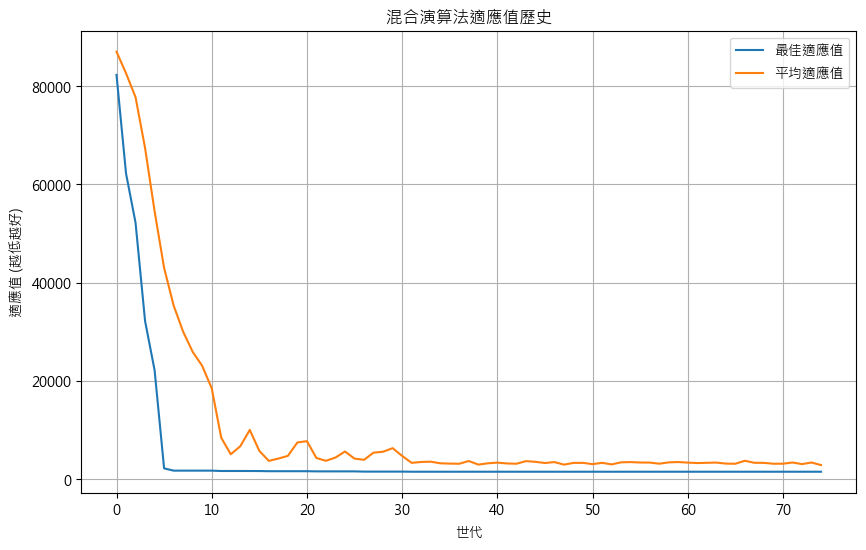


----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 25
C02：淘汰訂單數 = 0, 行駛距離 = 46
C03：淘汰訂單數 = 0, 行駛距離 = 36
C04：淘汰訂單數 = 0, 行駛距離 = 46
C05：淘汰訂單數 = 0, 行駛距離 = 48
C06：淘汰訂單數 = 0, 行駛距離 = 23
C07：淘汰訂單數 = 0, 行駛距離 = 31
C08：淘汰訂單數 = 0, 行駛距離 = 46
C09：淘汰訂單數 = 0, 行駛距離 = 30
C10：淘汰訂單數 = 0, 行駛距離 = 51
C11：淘汰訂單數 = 0, 行駛距離 = 39
C12：淘汰訂單數 = 0, 行駛距離 = 33
C13：淘汰訂單數 = 0, 行駛距離 = 33
C14：淘汰訂單數 = 0, 行駛距離 = 33
C15：淘汰訂單數 = 0, 行駛距離 = 30
C16：淘汰訂單數 = 0, 行駛距離 = 28
C17：淘汰訂單數 = 0, 行駛距離 = 44
C18：淘汰訂單數 = 0, 行駛距離 = 23
C19：淘汰訂單數 = 0, 行駛距離 = 51
C20：淘汰訂單數 = 0, 行駛距離 = 53
C21：淘汰訂單數 = 0, 行駛距離 = 40
C22：淘汰訂單數 = 0, 行駛距離 = 43
C23：淘汰訂單數 = 0, 行駛距離 = 51
C24：淘汰訂單數 = 0, 行駛距離 = 40
C25：淘汰訂單數 = 0, 行駛距離 = 31
C26：淘汰訂單數 = 0, 行駛距離 = 31
C27：淘汰訂單數 = 0, 行駛距離 = 56
C28：淘汰訂單數 = 0, 行駛距離 = 22
C29：淘汰訂單數 = 0, 行駛距離 = 41
C30：淘汰訂單數 = 0, 行駛距離 = 38
C31：淘汰訂單數 = 0, 行駛距離 = 36
C32：淘汰訂單數 = 0, 行駛距離 = 32
C33：淘汰訂單數 = 0, 行駛距離 = 27
C34：淘汰訂單數 = 0, 行駛距離 = 44
C35：淘汰訂單數 = 0, 行駛距離 = 51
C36：淘汰訂單數 = 0, 行駛距離 = 7
C37：淘汰訂單數 = 0, 行駛距離 = 35
C38：淘汰訂單數 = 0, 行駛距離 = 18
C39：淘汰訂單數 = 0, 行駛距離 = 33
C40

In [18]:
# 調整參數
scheduler.batch_capacity = 2

# 遺傳算法參數
scheduler.pop_size = 1000
scheduler.generations = 1000
scheduler.elite_size = 50
scheduler.mutation_rate = 0.4
scheduler.tournament_size = 10

scheduler.earlier_ga_stop = 50

# 禁忌搜索參數
scheduler.tabu_iterations = 50
scheduler.tabu_tenure = 10
scheduler.tabu_frequency = 5
scheduler.tabu_elite_ratio = 0.001
scheduler.rep = 5

scheduler.earlier_ts_stop = 40


# 修改適應值函數，納入時間因素
# scheduler.modify_fitness_function(include_time=True, time_weight=0.5)

# 執行混合算法
scheduler.run()

# 繪製演化歷史
scheduler.plot_history()

# 分析結果
metrics = scheduler.analyze_results()

# 保存結果到Excel
scheduler.save_results("optimized_schedule.xlsx")

# 查看最佳解的適應值
print(f"\n最佳解適應值: {scheduler.best_fit}")

## Capacity = 4

第 0 代發現更佳解，適應值：162038
第 0 代 | 最佳：162038.00 | 平均：166857.52
第 1 代發現更佳解，適應值：132017
第 2 代發現更佳解，適應值：112043
第 3 代發現更佳解，適應值：102000
第 4 代發現更佳解，適應值：81959
第 5 代發現更佳解，適應值：71910
    - 第 5 代 Tabu 搜索發現更佳解，適應值：1495
第 9 代發現更佳解，適應值：1489
    - 第 10 代 Tabu 搜索發現更佳解，適應值：1435
第 10 代 | 最佳：1435.00 | 平均：45098.83
第 14 代發現更佳解，適應值：1418
第 15 代發現更佳解，適應值：1404
    - 第 15 代 Tabu 搜索發現更佳解，適應值：1327
第 19 代發現更佳解，適應值：1323
第 20 代發現更佳解，適應值：1287
    - 第 20 代 Tabu 搜索發現更佳解，適應值：1248
第 20 代 | 最佳：1248.00 | 平均：14325.93
第 23 代發現更佳解，適應值：1227
第 25 代發現更佳解，適應值：1223
    - 第 25 代 Tabu 搜索發現更佳解，適應值：1209
第 26 代發現更佳解，適應值：1206
第 27 代發現更佳解，適應值：1184
第 28 代發現更佳解，適應值：1165
第 29 代發現更佳解，適應值：1158
第 30 代發現更佳解，適應值：1138
    - 第 30 代 Tabu 搜索發現更佳解，適應值：1128
第 30 代 | 最佳：1128.00 | 平均：5279.73
第 32 代發現更佳解，適應值：1124
第 33 代發現更佳解，適應值：1115
第 34 代發現更佳解，適應值：1113
第 38 代發現更佳解，適應值：1111
第 39 代發現更佳解，適應值：1109
第 40 代發現更佳解，適應值：1097
    - 第 40 代 Tabu 搜索發現更佳解，適應值：1096
第 40 代 | 最佳：1096.00 | 平均：2654.08
第 43 代發現更佳解，適應值：1095
第 44 代發現更佳解，適應值：1091
第 45 代發現更佳解，適應值：1090
    - 第 45 代 Tab

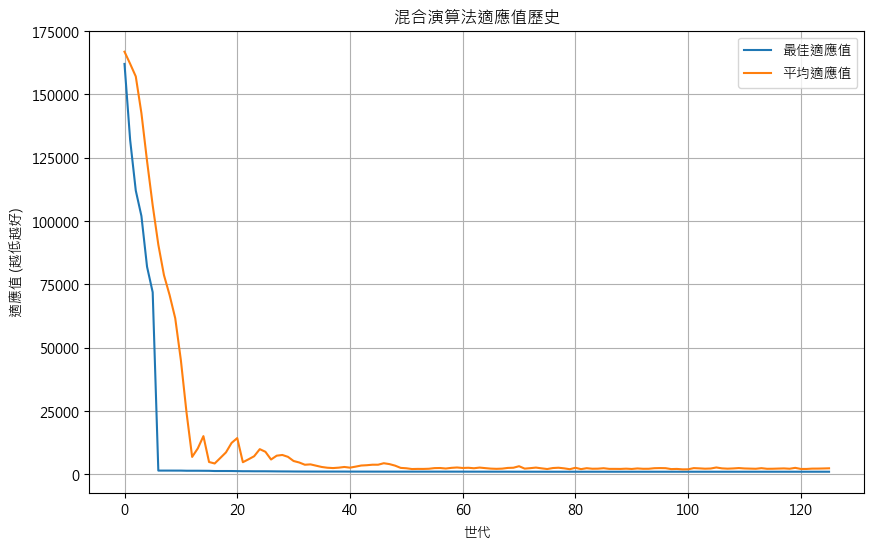


----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 0
C02：淘汰訂單數 = 0, 行駛距離 = 34
C03：淘汰訂單數 = 0, 行駛距離 = 35
C04：淘汰訂單數 = 0, 行駛距離 = 0
C05：淘汰訂單數 = 0, 行駛距離 = 46
C06：淘汰訂單數 = 0, 行駛距離 = 0
C07：淘汰訂單數 = 0, 行駛距離 = 51
C08：淘汰訂單數 = 0, 行駛距離 = 0
C09：淘汰訂單數 = 0, 行駛距離 = 41
C10：淘汰訂單數 = 0, 行駛距離 = 0
C11：淘汰訂單數 = 0, 行駛距離 = 56
C12：淘汰訂單數 = 0, 行駛距離 = 35
C13：淘汰訂單數 = 0, 行駛距離 = 0
C14：淘汰訂單數 = 0, 行駛距離 = 0
C15：淘汰訂單數 = 0, 行駛距離 = 0
C16：淘汰訂單數 = 0, 行駛距離 = 53
C17：淘汰訂單數 = 0, 行駛距離 = 43
C18：淘汰訂單數 = 0, 行駛距離 = 56
C19：淘汰訂單數 = 0, 行駛距離 = 53
C20：淘汰訂單數 = 0, 行駛距離 = 73
C21：淘汰訂單數 = 0, 行駛距離 = 45
C22：淘汰訂單數 = 0, 行駛距離 = 53
C23：淘汰訂單數 = 0, 行駛距離 = 7
C24：淘汰訂單數 = 0, 行駛距離 = 0
C25：淘汰訂單數 = 0, 行駛距離 = 42
C26：淘汰訂單數 = 0, 行駛距離 = 74
C27：淘汰訂單數 = 0, 行駛距離 = 50
C28：淘汰訂單數 = 0, 行駛距離 = 0
C29：淘汰訂單數 = 0, 行駛距離 = 0
C30：淘汰訂單數 = 0, 行駛距離 = 23
C31：淘汰訂單數 = 0, 行駛距離 = 0
C32：淘汰訂單數 = 0, 行駛距離 = 0
C33：淘汰訂單數 = 0, 行駛距離 = 0
C34：淘汰訂單數 = 0, 行駛距離 = 39
C35：淘汰訂單數 = 0, 行駛距離 = 40
C36：淘汰訂單數 = 0, 行駛距離 = 18
C37：淘汰訂單數 = 0, 行駛距離 = 42
C38：淘汰訂單數 = 0, 行駛距離 = 0
C39：淘汰訂單數 = 0, 行駛距離 = 0
C40：淘汰訂單數 = 0, 行駛距離

In [19]:
# 調整參數
scheduler.batch_capacity = 4

# 遺傳算法參數
scheduler.pop_size = 1000
scheduler.generations = 1000
scheduler.elite_size = 50
scheduler.mutation_rate = 0.4
scheduler.tournament_size = 10

scheduler.earlier_ga_stop = 50

# 禁忌搜索參數
scheduler.tabu_iterations = 50
scheduler.tabu_tenure = 10
scheduler.tabu_frequency = 5
scheduler.tabu_elite_ratio = 0.001
scheduler.rep = 5

scheduler.earlier_ts_stop = 40

# 修改適應值函數，納入時間因素
# scheduler.modify_fitness_function(include_time=True, time_weight=0.5)

# 執行混合算法
scheduler.run()

# 繪製演化歷史
scheduler.plot_history()

# 分析結果
metrics = scheduler.analyze_results()

# 保存結果到Excel
scheduler.save_results("optimized_schedule.xlsx")

# 查看最佳解的適應值
print(f"\n最佳解適應值: {scheduler.best_fit}")

## Capacity = 10

第 0 代發現更佳解，適應值：161988
第 0 代 | 最佳：161988.00 | 平均：167070.40
第 1 代發現更佳解，適應值：131983
第 2 代發現更佳解，適應值：111980
第 3 代發現更佳解，適應值：91956
第 4 代發現更佳解，適應值：71929
第 5 代發現更佳解，適應值：61829
    - 第 5 代 Tabu 搜索發現更佳解，適應值：1449
第 10 代發現更佳解，適應值：1429
    - 第 10 代 Tabu 搜索發現更佳解，適應值：1357
第 10 代 | 最佳：1357.00 | 平均：56429.64
第 14 代發現更佳解，適應值：1342
第 15 代發現更佳解，適應值：1337
    - 第 15 代 Tabu 搜索發現更佳解，適應值：1315
第 18 代發現更佳解，適應值：1276
第 19 代發現更佳解，適應值：1272
第 20 代發現更佳解，適應值：1255
    - 第 20 代 Tabu 搜索發現更佳解，適應值：1212
第 20 代 | 最佳：1212.00 | 平均：11540.64
第 23 代發現更佳解，適應值：1210
第 24 代發現更佳解，適應值：1165
    - 第 25 代 Tabu 搜索發現更佳解，適應值：1135
第 27 代發現更佳解，適應值：1111
第 28 代發現更佳解，適應值：1086
第 29 代發現更佳解，適應值：1071
第 30 代發現更佳解，適應值：1066
    - 第 30 代 Tabu 搜索發現更佳解，適應值：1049
第 30 代 | 最佳：1049.00 | 平均：14877.29
第 32 代發現更佳解，適應值：1040
第 34 代發現更佳解，適應值：1035
第 35 代發現更佳解，適應值：1033
    - 第 35 代 Tabu 搜索發現更佳解，適應值：1028
第 36 代發現更佳解，適應值：1004
第 39 代發現更佳解，適應值：955
第 40 代 | 最佳：955.00 | 平均：4652.08
第 41 代發現更佳解，適應值：941
第 42 代發現更佳解，適應值：938
第 43 代發現更佳解，適應值：936
第 44 代發現更佳解，適應值：923
第 45 代發現更佳解，適應值：919
第

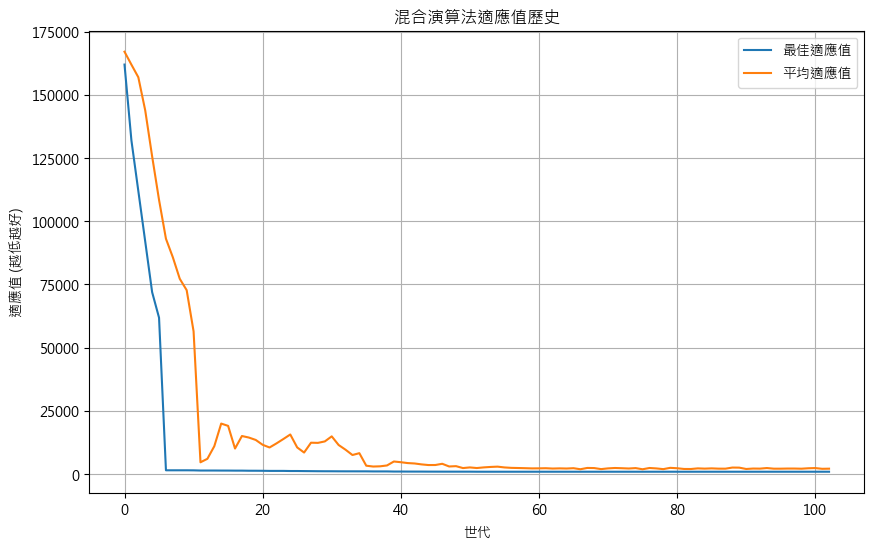


----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 0
C02：淘汰訂單數 = 0, 行駛距離 = 48
C03：淘汰訂單數 = 0, 行駛距離 = 23
C04：淘汰訂單數 = 0, 行駛距離 = 0
C05：淘汰訂單數 = 0, 行駛距離 = 0
C06：淘汰訂單數 = 0, 行駛距離 = 0
C07：淘汰訂單數 = 0, 行駛距離 = 51
C08：淘汰訂單數 = 0, 行駛距離 = 69
C09：淘汰訂單數 = 0, 行駛距離 = 0
C10：淘汰訂單數 = 0, 行駛距離 = 0
C11：淘汰訂單數 = 0, 行駛距離 = 46
C12：淘汰訂單數 = 0, 行駛距離 = 23
C13：淘汰訂單數 = 0, 行駛距離 = 40
C14：淘汰訂單數 = 0, 行駛距離 = 0
C15：淘汰訂單數 = 0, 行駛距離 = 56
C16：淘汰訂單數 = 0, 行駛距離 = 51
C17：淘汰訂單數 = 0, 行駛距離 = 0
C18：淘汰訂單數 = 0, 行駛距離 = 0
C19：淘汰訂單數 = 0, 行駛距離 = 0
C20：淘汰訂單數 = 0, 行駛距離 = 65
C21：淘汰訂單數 = 0, 行駛距離 = 30
C22：淘汰訂單數 = 0, 行駛距離 = 47
C23：淘汰訂單數 = 0, 行駛距離 = 0
C24：淘汰訂單數 = 0, 行駛距離 = 0
C25：淘汰訂單數 = 0, 行駛距離 = 40
C26：淘汰訂單數 = 0, 行駛距離 = 36
C27：淘汰訂單數 = 0, 行駛距離 = 0
C28：淘汰訂單數 = 0, 行駛距離 = 76
C29：淘汰訂單數 = 0, 行駛距離 = 0
C30：淘汰訂單數 = 0, 行駛距離 = 0
C31：淘汰訂單數 = 0, 行駛距離 = 55
C32：淘汰訂單數 = 0, 行駛距離 = 0
C33：淘汰訂單數 = 0, 行駛距離 = 38
C34：淘汰訂單數 = 0, 行駛距離 = 0
C35：淘汰訂單數 = 0, 行駛距離 = 18
C36：淘汰訂單數 = 0, 行駛距離 = 27
C37：淘汰訂單數 = 0, 行駛距離 = 0
C38：淘汰訂單數 = 0, 行駛距離 = 0
C39：淘汰訂單數 = 0, 行駛距離 = 0
C40：淘汰訂單數 = 0, 行駛距離 = 

In [20]:
# 調整參數
scheduler.batch_capacity = 10

# 遺傳算法參數
scheduler.pop_size = 1000
scheduler.generations = 1000
scheduler.elite_size = 50
scheduler.mutation_rate = 0.4
scheduler.tournament_size = 10

scheduler.earlier_ga_stop = 50

# 禁忌搜索參數
scheduler.tabu_iterations = 50
scheduler.tabu_tenure = 10
scheduler.tabu_frequency = 5
scheduler.tabu_elite_ratio = 0.001
scheduler.rep = 5

scheduler.earlier_ts_stop = 40

# 修改適應值函數，納入時間因素
# scheduler.modify_fitness_function(include_time=True, time_weight=0.5)

# 執行混合算法
scheduler.run()

# 繪製演化歷史
scheduler.plot_history()

# 分析結果
metrics = scheduler.analyze_results()

# 保存結果到Excel
scheduler.save_results("optimized_schedule.xlsx")

# 查看最佳解的適應值
print(f"\n最佳解適應值: {scheduler.best_fit}")

第 0 代發現更佳解，適應值：132047
第 0 代 | 最佳：132047.00 | 平均：132052.41
第 1 代發現更佳解，適應值：112041
第 2 代發現更佳解，適應值：92021
第 3 代發現更佳解，適應值：71948
第 4 代發現更佳解，適應值：71896
第 5 代發現更佳解，適應值：51900
    - 第 5 代 Tabu 搜索發現更佳解，適應值：1553
第 9 代發現更佳解，適應值：1528
第 10 代發現更佳解，適應值：1519
    - 第 10 代 Tabu 搜索發現更佳解，適應值：1451
第 10 代 | 最佳：1451.00 | 平均：7042.75
第 12 代發現更佳解，適應值：1442
第 13 代發現更佳解，適應值：1419
第 14 代發現更佳解，適應值：1396
第 15 代發現更佳解，適應值：1382
    - 第 15 代 Tabu 搜索發現更佳解，適應值：1329
第 18 代發現更佳解，適應值：1316
第 19 代發現更佳解，適應值：1273
第 20 代發現更佳解，適應值：1254
    - 第 20 代 Tabu 搜索發現更佳解，適應值：1223
第 20 代 | 最佳：1223.00 | 平均：22378.87
第 24 代發現更佳解，適應值：1204
第 25 代發現更佳解，適應值：1193
    - 第 25 代 Tabu 搜索發現更佳解，適應值：1168
第 26 代發現更佳解，適應值：1165
第 28 代發現更佳解，適應值：1155
第 30 代發現更佳解，適應值：1134
    - 第 30 代 Tabu 搜索發現更佳解，適應值：1085
第 30 代 | 最佳：1085.00 | 平均：13414.77
第 34 代發現更佳解，適應值：1067
第 35 代發現更佳解，適應值：1051
    - 第 35 代 Tabu 搜索發現更佳解，適應值：1014
第 38 代發現更佳解，適應值：1006
第 39 代發現更佳解，適應值：989
    - 第 40 代 Tabu 搜索發現更佳解，適應值：970
第 40 代 | 最佳：970.00 | 平均：13164.09
第 43 代發現更佳解，適應值：940
第 44 代發現更佳解，適應值：934
    - 第 

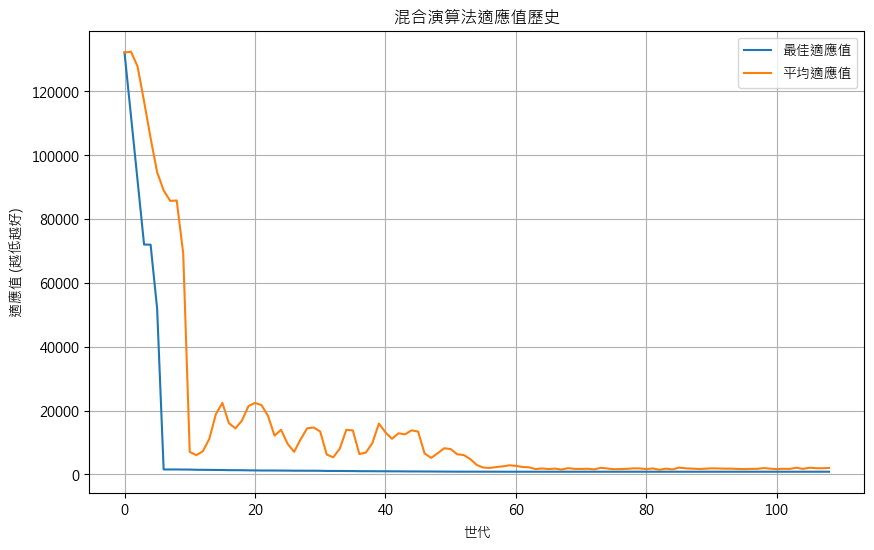


----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 0
C02：淘汰訂單數 = 0, 行駛距離 = 58
C03：淘汰訂單數 = 0, 行駛距離 = 0
C04：淘汰訂單數 = 0, 行駛距離 = 40
C05：淘汰訂單數 = 0, 行駛距離 = 0
C06：淘汰訂單數 = 0, 行駛距離 = 18
C07：淘汰訂單數 = 0, 行駛距離 = 0
C08：淘汰訂單數 = 0, 行駛距離 = 0
C09：淘汰訂單數 = 0, 行駛距離 = 52
C10：淘汰訂單數 = 0, 行駛距離 = 0
C11：淘汰訂單數 = 0, 行駛距離 = 0
C12：淘汰訂單數 = 0, 行駛距離 = 0
C13：淘汰訂單數 = 0, 行駛距離 = 0
C14：淘汰訂單數 = 0, 行駛距離 = 0
C15：淘汰訂單數 = 0, 行駛距離 = 0
C16：淘汰訂單數 = 0, 行駛距離 = 63
C17：淘汰訂單數 = 0, 行駛距離 = 0
C18：淘汰訂單數 = 0, 行駛距離 = 46
C19：淘汰訂單數 = 0, 行駛距離 = 39
C20：淘汰訂單數 = 0, 行駛距離 = 40
C21：淘汰訂單數 = 0, 行駛距離 = 76
C22：淘汰訂單數 = 0, 行駛距離 = 0
C23：淘汰訂單數 = 0, 行駛距離 = 37
C24：淘汰訂單數 = 0, 行駛距離 = 52
C25：淘汰訂單數 = 0, 行駛距離 = 34
C26：淘汰訂單數 = 0, 行駛距離 = 46
C27：淘汰訂單數 = 0, 行駛距離 = 0
C28：淘汰訂單數 = 0, 行駛距離 = 40
C29：淘汰訂單數 = 0, 行駛距離 = 56
C30：淘汰訂單數 = 0, 行駛距離 = 0
C31：淘汰訂單數 = 0, 行駛距離 = 38
C32：淘汰訂單數 = 0, 行駛距離 = 0
C33：淘汰訂單數 = 0, 行駛距離 = 0
C34：淘汰訂單數 = 0, 行駛距離 = 56
C35：淘汰訂單數 = 0, 行駛距離 = 0
C36：淘汰訂單數 = 0, 行駛距離 = 54
C37：淘汰訂單數 = 0, 行駛距離 = 0
C38：淘汰訂單數 = 0, 行駛距離 = 0
C39：淘汰訂單數 = 0, 行駛距離 = 0
C40：淘汰訂單數 = 0, 行駛距離 = 0

In [21]:
# 調整參數
scheduler.batch_capacity = 20

# 遺傳算法參數
scheduler.pop_size = 1000
scheduler.generations = 1000
scheduler.elite_size = 50
scheduler.mutation_rate = 0.4
scheduler.tournament_size = 10

scheduler.earlier_ga_stop = 50

# 禁忌搜索參數
scheduler.tabu_iterations = 50
scheduler.tabu_tenure = 10
scheduler.tabu_frequency = 5
scheduler.tabu_elite_ratio = 0.001
scheduler.rep = 5

scheduler.earlier_ts_stop = 40

# 修改適應值函數，納入時間因素
# scheduler.modify_fitness_function(include_time=True, time_weight=0.5)

# 執行混合算法
scheduler.run()

# 繪製演化歷史
scheduler.plot_history()

# 分析結果
metrics = scheduler.analyze_results()

# 保存結果到Excel
scheduler.save_results("optimized_schedule.xlsx")

# 查看最佳解的適應值
print(f"\n最佳解適應值: {scheduler.best_fit}")

---------------------------------------------------------------------------

In [22]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib
from joblib import Parallel, delayed
import time

class GaTabuScheduler:
    """使用遺傳算法的排程器 (移除 tabu search 部分)"""
    
    def __init__(self, data_file="data.xlsx", seed=42):
        """初始化排程器，讀取資料並設定預設參數，同時預處理數據以提升效能"""
        # 設定中文字型避免中文亂碼
        matplotlib.rcParams['font.sans-serif'] = ['Microsoft JhengHei','SimHei','Arial Unicode MS']
        matplotlib.rcParams['axes.unicode_minus'] = False
        
        # 設定隨機種子
        random.seed(seed)
        np.random.seed(seed)
        
        # 讀取資料（只讀一次，後續改用內存中的 dictionary）
        self.df_cart = pd.read_excel(data_file, sheet_name="CART")
        self.df_wip  = pd.read_excel(data_file, sheet_name="WIP")
        self.df_xfer = pd.read_excel(data_file, sheet_name="XFER_TIME")
        
        # 將 CART 與 WIP 資料轉成 dictionary 以加速查詢
        self.carts = {row["CART_ID"]: row for _, row in self.df_cart.iterrows()}
        self.wips = {row["WIP_ID"]: row for _, row in self.df_wip.iterrows()}
        
        # 建立 XFER_TIME 快速查表
        self.xfer_dict = {}
        for _, row in self.df_xfer.iterrows():
            frm = row["FROM"]
            to = row["TO"]
            if frm not in self.xfer_dict:
                self.xfer_dict[frm] = {}
            self.xfer_dict[frm][to] = row["XFER_TIME"]
        
        # 遺傳演算法參數
        self.pop_size = 50         # 族群大小
        self.generations = 500     # 進化世代數
        self.elite_size = 10       # 精英保留數
        self.mutation_rate = 0.4   # 突變率
        self.tournament_size = 10  # 錦標賽選擇樣本數
        self.batch_capacity = 2    # 每台 CART 一次最多接受的訂單數
        self.earlier_ga_stop = 20  # 連續多少代無改善就提前終止
        
        # 初始化結果變數
        self.best_solution = None
        self.best_fit = float('inf')
        self.best_details = None
        self.best_metrics = None
        self.evolution_history = {"best": [], "avg": []}
        self.execution_time = 0
    
    def repair_chromosome(self, chromosome):
        """修正函式：確保每台 CART 的訂單數不超過容量，且每個訂單只排入一次"""
        assigned = set()
        for cart in chromosome:
            new_list = []
            for w in chromosome[cart]:
                if w not in assigned and len(new_list) < self.batch_capacity:
                    new_list.append(w)
                    assigned.add(w)
            chromosome[cart] = new_list
        
        global_orders = set(self.df_wip["WIP_ID"].tolist())
        missing = list(global_orders - assigned)
        random.shuffle(missing)
        
        for order in missing:
            added = False
            for cart in chromosome:
                if len(chromosome[cart]) < self.batch_capacity:
                    chromosome[cart].append(order)
                    assigned.add(order)
                    added = True
                    break
            if not added:
                cart = random.choice(list(chromosome.keys()))
                idx = random.randrange(len(chromosome[cart]))
                chromosome[cart][idx] = order
                assigned.add(order)
        
        return chromosome
    
    def init_population(self, pop_size):
        """基因初始族群產生：每台 CART 挑選訂單後隨機排列產生初始解"""
        population = []
        wip_ids = self.df_wip["WIP_ID"].tolist()
        random.shuffle(wip_ids)
        cart_ids = self.df_cart["CART_ID"].tolist()
        
        base_assignment = {cart: [] for cart in cart_ids}
        for w in wip_ids:
            available = [c for c in cart_ids if len(base_assignment[c]) < self.batch_capacity]
            if available:
                chosen = random.choice(available)
                base_assignment[chosen].append(w)
        
        for _ in range(pop_size):
            chromosome = {}
            for cart in cart_ids:
                orders = base_assignment[cart].copy()
                random.shuffle(orders)
                chromosome[cart] = orders
            population.append(chromosome)
        
        return population
    
    def generate_mixed_sequence(self, wip_list):
        """
        生成最佳操作序列（pickup 和 delivery 混合排序）：
        採用貪心法，從當前位置出發，每次在所有可執行的操作中選取距離最近的，
        其中可執行操作包含：
          - 尚未 pickup 的訂單 (pickup)
          - 已 pickup 但尚未 delivery 的訂單 (delivery)
        """
        if not wip_list:
            return []
        
        start_loc = list(self.xfer_dict.keys())[0]
        current_loc = start_loc
        
        pending_pickups = wip_list.copy()
        pending_deliveries = []
        sequence = []
        
        while pending_pickups or pending_deliveries:
            candidates = []
            for w in pending_pickups:
                pickup_loc = self.wips[w]["FROM"]
                d = self.xfer_dict[current_loc].get(pickup_loc, float('inf'))
                candidates.append(("pickup", w, d, pickup_loc))
            for w in pending_deliveries:
                delivery_loc = self.wips[w]["TO"]
                d = self.xfer_dict[current_loc].get(delivery_loc, float('inf'))
                candidates.append(("delivery", w, d, delivery_loc))
            if not candidates:
                break
            op, w, _, next_loc = min(candidates, key=lambda x: x[2])
            sequence.append((op, w))
            current_loc = next_loc
            if op == "pickup":
                pending_pickups.remove(w)
                pending_deliveries.append(w)
            else:
                pending_deliveries.remove(w)
        
        return sequence
    
    def evaluate_cart(self, cart, wip_list):
        """評估單台 CART 的運作：根據操作序列計算超時訂單數和總行駛距離"""
        init_loc = self.carts[cart]["INIT_LOC"]
        current_loc = init_loc
        time_elapsed = 0
        distance = 0
        schedule = []
        rejections = 0
        
        if len(wip_list) == 0:
            return 0, 0, 0, []
        
        ops = self.generate_mixed_sequence(wip_list)
        for op, wip in ops:
            info = self.wips[wip]
            if op == "pickup":
                loc = info["FROM"]
                d = self.xfer_dict[current_loc][loc]
                distance += d
                time_elapsed += d
                schedule.append({'wip_id': wip, 'action': 'PICKUP', 'location': loc, 'time': time_elapsed})
                current_loc = loc
            else:
                loc = info["TO"]
                d = self.xfer_dict[current_loc][loc]
                distance += d
                time_elapsed += d
                schedule.append({'wip_id': wip, 'action': 'DELIVERY', 'location': loc, 'time': time_elapsed})
                if time_elapsed > info["Remaining Q-Time"]:
                    rejections += 1
                current_loc = loc
        
        return rejections, distance, time_elapsed, schedule
    
    def fitness(self, chromosome):
        """計算整體染色體的適應值，同時回傳各 CART 的詳細排程與指標"""
        total_rejections = 0
        total_distance = 0
        cart_details = {}
        cart_metrics = {}
        for cart, orders in chromosome.items():
            orders = orders[:self.batch_capacity]
            rej, dist, finish_time, sched = self.evaluate_cart(cart, orders)
            total_rejections += rej
            total_distance += dist
            cart_details[cart] = sched
            cart_metrics[cart] = {"rejections": rej, "distance": dist, "completion_time": finish_time}
        fit_val = total_rejections * 10000 + total_distance
        return fit_val, cart_details, cart_metrics
    
    def crossover(self, p1, p2):
        """交配：對兩個父代染色體採取 CART 分半交配後修正"""
        child = {}
        cart_ids = list(p1.keys())
        random.shuffle(cart_ids)
        half = len(cart_ids) // 2
        assigned = set()
        for cart in cart_ids[:half]:
            child[cart] = p1[cart].copy()
            assigned.update(p1[cart])
        for cart in cart_ids[half:]:
            lst = [w for w in p2[cart] if w not in assigned]
            child[cart] = lst
            assigned.update(lst)
        child = self.repair_chromosome(child)
        return child
    
    def mutate(self, chromosome):
        """突變：隨機從兩台 CART 中交換一筆訂單"""
        if random.random() > self.mutation_rate:
            return chromosome
        mutated = {c: v.copy() for c, v in chromosome.items()}
        carts_list = list(mutated.keys())
        c1, c2 = random.sample(carts_list, 2)
        if mutated[c1] and mutated[c2]:
            i = random.randrange(len(mutated[c1]))
            j = random.randrange(len(mutated[c2]))
            mutated[c1][i], mutated[c2][j] = mutated[c2][j], mutated[c1][i]
        mutated = self.repair_chromosome(mutated)
        return mutated

    def tournament_selection(self, population, fitness_details):
        """錦標賽選擇"""
        selected = random.sample(range(len(population)), self.tournament_size)
        best = min(selected, key=lambda i: fitness_details[i][0])
        return population[best]
    
    def run(self):
        """執行純 GA 搜尋"""
        start_time = time.time()
        population = self.init_population(self.pop_size)
        self.evolution_history = {"best": [], "avg": []}
        self.best_solution = None
        self.best_fit = float('inf')
        self.best_details = None
        self.best_metrics = None
        no_update_count = 0
        ga_update_threshold = self.earlier_ga_stop
        for gen in range(self.generations):
            fits_details = [self.fitness(chrom) for chrom in population]
            fits = [fd[0] for fd in fits_details]
            details_list = [fd[1] for fd in fits_details]
            metrics_list = [fd[2] for fd in fits_details]
            best_idx = fits.index(min(fits))
            best_gen_fit = fits[best_idx]
            self.evolution_history["best"].append(best_gen_fit)
            self.evolution_history["avg"].append(sum(fits) / len(fits))
            if best_gen_fit < self.best_fit:
                self.best_fit = best_gen_fit
                self.best_solution = population[best_idx]
                self.best_details = details_list[best_idx]
                self.best_metrics = metrics_list[best_idx]
                no_update_count = 0
                print(f"第 {gen} 代發現更佳解，適應值：{best_gen_fit}")
            else:
                no_update_count += 1
            if no_update_count >= ga_update_threshold:
                print(f"連續 {ga_update_threshold} 代無改善，提前終止 GA 搜尋")
                break
            
            elite_indices = sorted(range(len(fits)), key=lambda i: fits[i])[:self.elite_size]
            new_population = [population[i] for i in elite_indices]
            while len(new_population) < self.pop_size:
                parent1 = self.tournament_selection(population, fits_details)
                parent2 = self.tournament_selection(population, fits_details)
                if random.random() < 0.8:
                    child = self.crossover(parent1, parent2)
                else:
                    child = {c: v.copy() for c, v in parent1.items()}
                child = self.mutate(child)
                new_population.append(child)
            population = new_population
            if gen % 10 == 0:
                print(f"第 {gen} 代 | 最佳：{best_gen_fit:.2f} | 平均：{sum(fits)/len(fits):.2f}")
                
        self.execution_time = time.time() - start_time
        print(f"\n執行時間: {self.execution_time:.2f} 秒")
        return self.best_solution, self.best_fit, self.best_details, self.best_metrics
    
    def plot_history(self):
        """繪製演化歷史圖"""
        plt.figure(figsize=(10,6))
        plt.plot(self.evolution_history["best"], label="最佳適應值")
        plt.plot(self.evolution_history["avg"], label="平均適應值")
        plt.xlabel("世代")
        plt.ylabel("適應值 (越低越好)")
        plt.title("演算法適應值歷史")
        plt.legend()
        plt.grid(True)
        plt.savefig("fitness_history.png", dpi=300)
        plt.show()
    
    def generate_schedule(self):
        """根據結果生成最終排程"""
        if self.best_details is None:
            print("請先執行 run() 方法產生結果")
            return None
        output = []
        for cart, events in self.best_details.items():
            order = 1
            for ev in events:
                output.append([cart, order, ev['wip_id'], ev['action'].upper(), ev['time']])
                order += 1
        return pd.DataFrame(output, columns=["CART_ID", "ORDER", "WIP_ID", "ACTION", "COMPLETE_TIME"])
    
    def analyze_results(self):
        """分析最終結果"""
        if self.best_metrics is None:
            print("請先執行 run() 方法產生結果")
            return
        print("\n----- 各 CART 指標 -----")
        total_rej = 0
        total_dist = 0
        max_time = 0
        for cart in sorted(self.best_metrics.keys()):
            m = self.best_metrics[cart]
            total_rej += m["rejections"]
            total_dist += m["distance"]
            if m["completion_time"] > max_time:
                max_time = m["completion_time"]
            print(f"{cart}：淘汰訂單數 = {m['rejections']}, 行駛距離 = {m['distance']}")
        print("\n---- 總計 ----")
        print(f"總淘汰訂單數 = {total_rej}")
        print(f"總行駛距離 = {total_dist}")
        print(f"所有 CART 最後完成時間 = {max_time}")
        calculated_fit = total_rej * 10000 + total_dist
        if calculated_fit != self.best_fit:
            print(f"警告: 計算適應值 ({calculated_fit}) 與報告值 ({self.best_fit}) 不符")
        return {"total_rejections": total_rej, "total_distance": total_dist, "max_completion_time": max_time}
    
    def save_results(self, filename="schedule_result.xlsx"):
        """保存最終排程結果到 Excel 檔案"""
        schedule = self.generate_schedule()
        if schedule is not None:
            schedule.to_excel(filename, index=False)
            print(f"\n排程結果已保存至 '{filename}'")
    
    def modify_fitness_function(self, include_time=False, time_weight=0.5):
        """修改適應值函數，可選擇是否納入時間因素"""
        if include_time:
            print(f"修改適應值函數：加入時間因素 (權重 = {time_weight})")
            self.fitness = lambda chromosome: self._fitness_with_time(chromosome, time_weight)
        else:
            print("恢復標準適應值函數：不考慮時間因素")
            self.fitness = self._fitness_standard
    
    def _fitness_standard(self, chromosome):
        """標準適應值函數：只考慮訂單淘汰數和行駛距離"""
        total_rejections = 0
        total_distance = 0
        cart_details = {}
        cart_metrics = {}
        for cart, orders in chromosome.items():
            orders = orders[:self.batch_capacity]
            rej, dist, finish_time, sched = self.evaluate_cart(cart, orders)
            total_rejections += rej
            total_distance += dist
            cart_details[cart] = sched
            cart_metrics[cart] = {"rejections": rej, "distance": dist, "completion_time": finish_time}
        fit_val = total_rejections * 10000 + total_distance
        return fit_val, cart_details, cart_metrics
    
    def _fitness_with_time(self, chromosome, time_weight=0.5):
        """考慮時間的適應值函數：納入最大完成時間"""
        total_rejections = 0
        total_distance = 0
        max_completion_time = 0
        cart_details = {}
        cart_metrics = {}
        for cart, orders in chromosome.items():
            orders = orders[:self.batch_capacity]
            rej, dist, finish_time, sched = self.evaluate_cart(cart, orders)
            total_rejections += rej
            total_distance += dist
            max_completion_time = max(max_completion_time, finish_time)
            cart_details[cart] = sched
            cart_metrics[cart] = {"rejections": rej, "distance": dist, "completion_time": finish_time}
        fit_val = total_rejections * 10000 + total_distance + max_completion_time * time_weight
        return fit_val, cart_details, cart_metrics

In [23]:
# 創建排程器實例
scheduler = GaTabuScheduler(data_file="data2.xlsx")

第 0 代發現更佳解，適應值：82321
第 0 代 | 最佳：82321.00 | 平均：87044.30
第 1 代發現更佳解，適應值：62245
第 2 代發現更佳解，適應值：52198
第 3 代發現更佳解，適應值：32182
第 4 代發現更佳解，適應值：22165
第 5 代發現更佳解，適應值：2160
第 6 代發現更佳解，適應值：2139
第 7 代發現更佳解，適應值：2098
第 8 代發現更佳解，適應值：2077
第 9 代發現更佳解，適應值：2036
第 10 代發現更佳解，適應值：2027
第 10 代 | 最佳：2027.00 | 平均：13379.23
第 11 代發現更佳解，適應值：2014
第 12 代發現更佳解，適應值：1971
第 13 代發現更佳解，適應值：1954
第 15 代發現更佳解，適應值：1940
第 16 代發現更佳解，適應值：1921
第 17 代發現更佳解，適應值：1918
第 18 代發現更佳解，適應值：1902
第 19 代發現更佳解，適應值：1869
第 20 代發現更佳解，適應值：1849
第 20 代 | 最佳：1849.00 | 平均：7001.18
第 21 代發現更佳解，適應值：1848
第 23 代發現更佳解，適應值：1792
第 25 代發現更佳解，適應值：1783
第 26 代發現更佳解，適應值：1781
第 27 代發現更佳解，適應值：1767
第 28 代發現更佳解，適應值：1752
第 29 代發現更佳解，適應值：1742
第 30 代發現更佳解，適應值：1735
第 30 代 | 最佳：1735.00 | 平均：4261.42
第 31 代發現更佳解，適應值：1724
第 32 代發現更佳解，適應值：1710
第 33 代發現更佳解，適應值：1709
第 34 代發現更佳解，適應值：1691
第 35 代發現更佳解，適應值：1683
第 36 代發現更佳解，適應值：1661
第 37 代發現更佳解，適應值：1656
第 38 代發現更佳解，適應值：1645
第 39 代發現更佳解，適應值：1641
第 40 代發現更佳解，適應值：1631
第 40 代 | 最佳：1631.00 | 平均：6223.83
第 42 代發現更佳解，適應值：1623
第 44 代發現更佳解，適應值：161

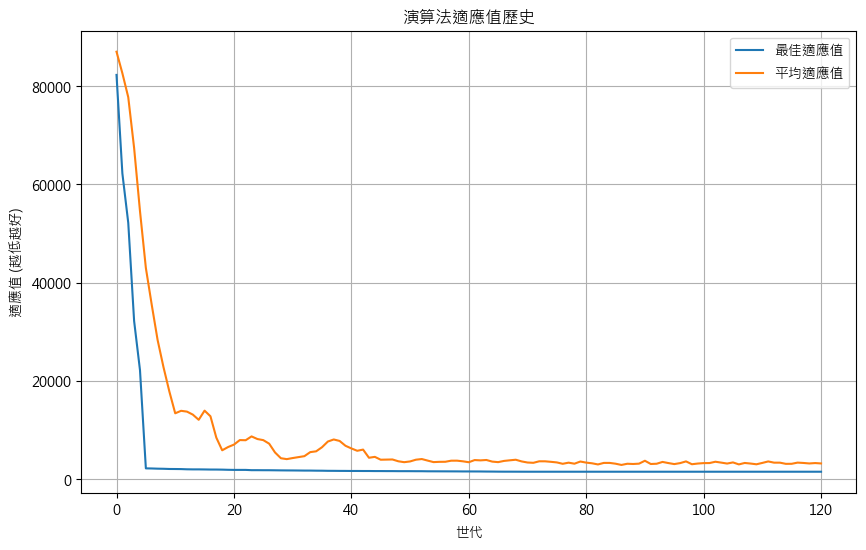


----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 33
C02：淘汰訂單數 = 0, 行駛距離 = 7
C03：淘汰訂單數 = 0, 行駛距離 = 31
C04：淘汰訂單數 = 0, 行駛距離 = 46
C05：淘汰訂單數 = 0, 行駛距離 = 51
C06：淘汰訂單數 = 0, 行駛距離 = 25
C07：淘汰訂單數 = 0, 行駛距離 = 33
C08：淘汰訂單數 = 0, 行駛距離 = 44
C09：淘汰訂單數 = 0, 行駛距離 = 36
C10：淘汰訂單數 = 0, 行駛距離 = 23
C11：淘汰訂單數 = 0, 行駛距離 = 39
C12：淘汰訂單數 = 0, 行駛距離 = 35
C13：淘汰訂單數 = 0, 行駛距離 = 46
C14：淘汰訂單數 = 0, 行駛距離 = 30
C15：淘汰訂單數 = 0, 行駛距離 = 31
C16：淘汰訂單數 = 0, 行駛距離 = 56
C17：淘汰訂單數 = 0, 行駛距離 = 27
C18：淘汰訂單數 = 0, 行駛距離 = 18
C19：淘汰訂單數 = 0, 行駛距離 = 40
C20：淘汰訂單數 = 0, 行駛距離 = 51
C21：淘汰訂單數 = 0, 行駛距離 = 51
C22：淘汰訂單數 = 0, 行駛距離 = 48
C23：淘汰訂單數 = 0, 行駛距離 = 46
C24：淘汰訂單數 = 0, 行駛距離 = 31
C25：淘汰訂單數 = 0, 行駛距離 = 43
C26：淘汰訂單數 = 0, 行駛距離 = 38
C27：淘汰訂單數 = 0, 行駛距離 = 30
C28：淘汰訂單數 = 0, 行駛距離 = 32
C29：淘汰訂單數 = 0, 行駛距離 = 41
C30：淘汰訂單數 = 0, 行駛距離 = 40
C31：淘汰訂單數 = 0, 行駛距離 = 44
C32：淘汰訂單數 = 0, 行駛距離 = 36
C33：淘汰訂單數 = 0, 行駛距離 = 53
C34：淘汰訂單數 = 0, 行駛距離 = 51
C35：淘汰訂單數 = 0, 行駛距離 = 33
C36：淘汰訂單數 = 0, 行駛距離 = 22
C37：淘汰訂單數 = 0, 行駛距離 = 23
C38：淘汰訂單數 = 0, 行駛距離 = 28
C39：淘汰訂單數 = 0, 行駛距離 = 33
C40

In [24]:
# 調整參數
scheduler.batch_capacity = 2

# 遺傳算法參數
scheduler.pop_size = 1000
scheduler.generations = 1000
scheduler.elite_size = 50
scheduler.mutation_rate = 0.4
scheduler.tournament_size = 10

scheduler.earlier_ga_stop = 50



# 修改適應值函數，納入時間因素
# scheduler.modify_fitness_function(include_time=True, time_weight=0.5)

# 執行混合算法
scheduler.run()

# 繪製演化歷史
scheduler.plot_history()

# 分析結果
metrics = scheduler.analyze_results()

# 保存結果到Excel
scheduler.save_results("optimized_schedule.xlsx")

# 查看最佳解的適應值
print(f"\n最佳解適應值: {scheduler.best_fit}")

第 0 代發現更佳解，適應值：151961
第 0 代 | 最佳：151961.00 | 平均：161872.84
第 1 代發現更佳解，適應值：131936
第 2 代發現更佳解，適應值：111942
第 3 代發現更佳解，適應值：91914
第 4 代發現更佳解，適應值：71978
第 5 代發現更佳解，適應值：51875
第 6 代發現更佳解，適應值：31984
第 7 代發現更佳解，適應值：31847
第 8 代發現更佳解，適應值：31832
第 9 代發現更佳解，適應值：11993
第 10 代發現更佳解，適應值：11866
第 10 代 | 最佳：11866.00 | 平均：48544.90
第 11 代發現更佳解，適應值：1841
第 12 代發現更佳解，適應值：1816
第 13 代發現更佳解，適應值：1785
第 14 代發現更佳解，適應值：1772
第 15 代發現更佳解，適應值：1761
第 17 代發現更佳解，適應值：1729
第 18 代發現更佳解，適應值：1698
第 19 代發現更佳解，適應值：1689
第 20 代發現更佳解，適應值：1679
第 20 代 | 最佳：1679.00 | 平均：20710.03
第 21 代發現更佳解，適應值：1665
第 22 代發現更佳解，適應值：1596
第 24 代發現更佳解，適應值：1566
第 25 代發現更佳解，適應值：1544
第 26 代發現更佳解，適應值：1537
第 28 代發現更佳解，適應值：1503
第 29 代發現更佳解，適應值：1483
第 30 代發現更佳解，適應值：1450
第 30 代 | 最佳：1450.00 | 平均：11189.14
第 32 代發現更佳解，適應值：1413
第 34 代發現更佳解，適應值：1405
第 35 代發現更佳解，適應值：1393
第 36 代發現更佳解，適應值：1387
第 37 代發現更佳解，適應值：1371
第 38 代發現更佳解，適應值：1356
第 39 代發現更佳解，適應值：1327
第 40 代發現更佳解，適應值：1321
第 40 代 | 最佳：1321.00 | 平均：4647.28
第 41 代發現更佳解，適應值：1308
第 42 代發現更佳解，適應值：1279
第 43 代發現更佳解，適應值：1275
第 44 

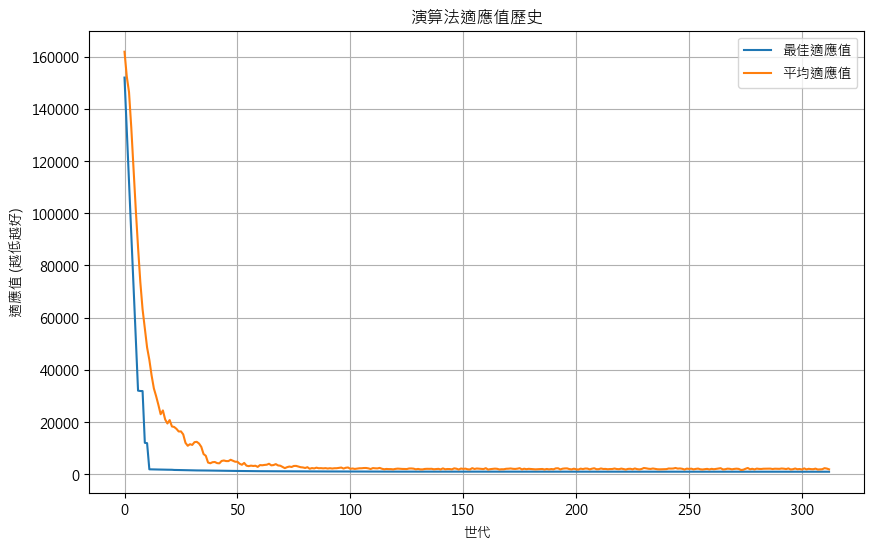


----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 40
C02：淘汰訂單數 = 0, 行駛距離 = 54
C03：淘汰訂單數 = 0, 行駛距離 = 46
C04：淘汰訂單數 = 0, 行駛距離 = 46
C05：淘汰訂單數 = 0, 行駛距離 = 0
C06：淘汰訂單數 = 0, 行駛距離 = 33
C07：淘汰訂單數 = 0, 行駛距離 = 0
C08：淘汰訂單數 = 0, 行駛距離 = 37
C09：淘汰訂單數 = 0, 行駛距離 = 42
C10：淘汰訂單數 = 0, 行駛距離 = 7
C11：淘汰訂單數 = 0, 行駛距離 = 53
C12：淘汰訂單數 = 0, 行駛距離 = 0
C13：淘汰訂單數 = 0, 行駛距離 = 51
C14：淘汰訂單數 = 0, 行駛距離 = 0
C15：淘汰訂單數 = 0, 行駛距離 = 0
C16：淘汰訂單數 = 0, 行駛距離 = 36
C17：淘汰訂單數 = 0, 行駛距離 = 0
C18：淘汰訂單數 = 0, 行駛距離 = 0
C19：淘汰訂單數 = 0, 行駛距離 = 46
C20：淘汰訂單數 = 0, 行駛距離 = 0
C21：淘汰訂單數 = 0, 行駛距離 = 47
C22：淘汰訂單數 = 0, 行駛距離 = 0
C23：淘汰訂單數 = 0, 行駛距離 = 0
C24：淘汰訂單數 = 0, 行駛距離 = 40
C25：淘汰訂單數 = 0, 行駛距離 = 0
C26：淘汰訂單數 = 0, 行駛距離 = 58
C27：淘汰訂單數 = 0, 行駛距離 = 0
C28：淘汰訂單數 = 0, 行駛距離 = 0
C29：淘汰訂單數 = 0, 行駛距離 = 35
C30：淘汰訂單數 = 0, 行駛距離 = 0
C31：淘汰訂單數 = 0, 行駛距離 = 0
C32：淘汰訂單數 = 0, 行駛距離 = 0
C33：淘汰訂單數 = 0, 行駛距離 = 0
C34：淘汰訂單數 = 0, 行駛距離 = 44
C35：淘汰訂單數 = 0, 行駛距離 = 46
C36：淘汰訂單數 = 0, 行駛距離 = 64
C37：淘汰訂單數 = 0, 行駛距離 = 0
C38：淘汰訂單數 = 0, 行駛距離 = 0
C39：淘汰訂單數 = 0, 行駛距離 = 43
C40：淘汰訂單數 = 0, 行駛距離 = 

In [25]:
# 調整參數
scheduler.batch_capacity = 4

# 遺傳算法參數
scheduler.pop_size = 1000
scheduler.generations = 1000
scheduler.elite_size = 50
scheduler.mutation_rate = 0.4
scheduler.tournament_size = 10

scheduler.earlier_ga_stop = 50



# 修改適應值函數，納入時間因素
# scheduler.modify_fitness_function(include_time=True, time_weight=0.5)

# 執行混合算法
scheduler.run()

# 繪製演化歷史
scheduler.plot_history()

# 分析結果
metrics = scheduler.analyze_results()

# 保存結果到Excel
scheduler.save_results("optimized_schedule.xlsx")

# 查看最佳解的適應值
print(f"\n最佳解適應值: {scheduler.best_fit}")

第 0 代發現更佳解，適應值：131896
第 0 代 | 最佳：131896.00 | 平均：131897.55
第 1 代發現更佳解，適應值：111887
第 2 代發現更佳解，適應值：101828
第 3 代發現更佳解，適應值：81812
第 4 代發現更佳解，適應值：61760
第 6 代發現更佳解，適應值：51770
第 7 代發現更佳解，適應值：41749
第 8 代發現更佳解，適應值：21804
第 10 代發現更佳解，適應值：21797
第 10 代 | 最佳：21797.00 | 平均：62872.71
第 11 代發現更佳解，適應值：11870
第 12 代發現更佳解，適應值：11785
第 13 代發現更佳解，適應值：1847
第 14 代發現更佳解，適應值：1818
第 15 代發現更佳解，適應值：1787
第 16 代發現更佳解，適應值：1722
第 17 代發現更佳解，適應值：1690
第 18 代發現更佳解，適應值：1613
第 20 代發現更佳解，適應值：1606
第 20 代 | 最佳：1606.00 | 平均：19891.31
第 22 代發現更佳解，適應值：1585
第 23 代發現更佳解，適應值：1550
第 24 代發現更佳解，適應值：1540
第 25 代發現更佳解，適應值：1492
第 26 代發現更佳解，適應值：1490
第 27 代發現更佳解，適應值：1421
第 30 代發現更佳解，適應值：1383
第 30 代 | 最佳：1383.00 | 平均：22629.63
第 31 代發現更佳解，適應值：1377
第 32 代發現更佳解，適應值：1364
第 33 代發現更佳解，適應值：1326
第 34 代發現更佳解，適應值：1285
第 36 代發現更佳解，適應值：1253
第 37 代發現更佳解，適應值：1242
第 38 代發現更佳解，適應值：1227
第 39 代發現更佳解，適應值：1192
第 40 代發現更佳解，適應值：1147
第 40 代 | 最佳：1147.00 | 平均：11070.73
第 42 代發現更佳解，適應值：1111
第 43 代發現更佳解，適應值：1054
第 45 代發現更佳解，適應值：1050
第 46 代發現更佳解，適應值：1035
第 47 代發現更佳解，適應值：1015
第 

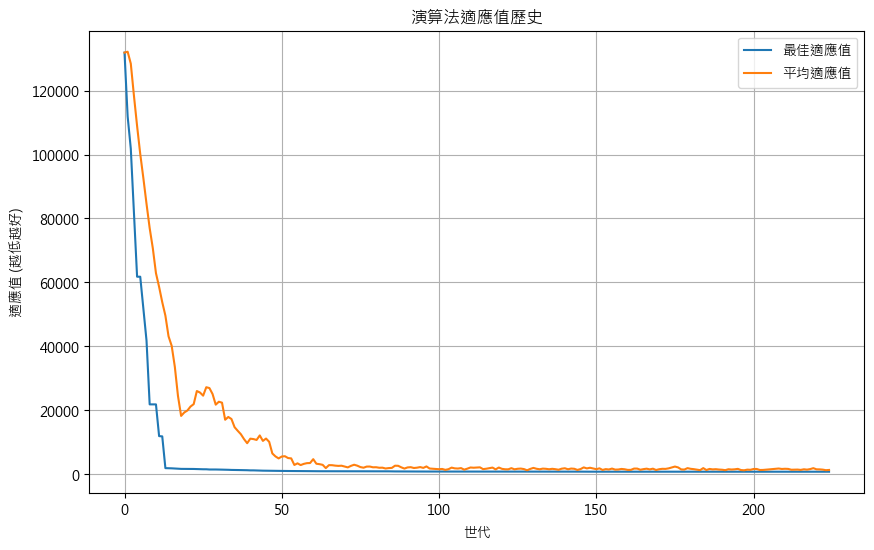


----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 0
C02：淘汰訂單數 = 0, 行駛距離 = 48
C03：淘汰訂單數 = 0, 行駛距離 = 71
C04：淘汰訂單數 = 0, 行駛距離 = 40
C05：淘汰訂單數 = 0, 行駛距離 = 0
C06：淘汰訂單數 = 0, 行駛距離 = 0
C07：淘汰訂單數 = 0, 行駛距離 = 0
C08：淘汰訂單數 = 0, 行駛距離 = 0
C09：淘汰訂單數 = 0, 行駛距離 = 44
C10：淘汰訂單數 = 0, 行駛距離 = 55
C11：淘汰訂單數 = 0, 行駛距離 = 0
C12：淘汰訂單數 = 0, 行駛距離 = 0
C13：淘汰訂單數 = 0, 行駛距離 = 0
C14：淘汰訂單數 = 0, 行駛距離 = 0
C15：淘汰訂單數 = 0, 行駛距離 = 0
C16：淘汰訂單數 = 0, 行駛距離 = 64
C17：淘汰訂單數 = 0, 行駛距離 = 0
C18：淘汰訂單數 = 0, 行駛距離 = 0
C19：淘汰訂單數 = 0, 行駛距離 = 0
C20：淘汰訂單數 = 0, 行駛距離 = 0
C21：淘汰訂單數 = 0, 行駛距離 = 0
C22：淘汰訂單數 = 0, 行駛距離 = 0
C23：淘汰訂單數 = 0, 行駛距離 = 76
C24：淘汰訂單數 = 0, 行駛距離 = 0
C25：淘汰訂單數 = 0, 行駛距離 = 85
C26：淘汰訂單數 = 0, 行駛距離 = 46
C27：淘汰訂單數 = 0, 行駛距離 = 0
C28：淘汰訂單數 = 0, 行駛距離 = 40
C29：淘汰訂單數 = 0, 行駛距離 = 0
C30：淘汰訂單數 = 0, 行駛距離 = 0
C31：淘汰訂單數 = 0, 行駛距離 = 0
C32：淘汰訂單數 = 0, 行駛距離 = 0
C33：淘汰訂單數 = 0, 行駛距離 = 0
C34：淘汰訂單數 = 0, 行駛距離 = 40
C35：淘汰訂單數 = 0, 行駛距離 = 63
C36：淘汰訂單數 = 0, 行駛距離 = 0
C37：淘汰訂單數 = 0, 行駛距離 = 52
C38：淘汰訂單數 = 0, 行駛距離 = 0
C39：淘汰訂單數 = 0, 行駛距離 = 0
C40：淘汰訂單數 = 0, 行駛距離 = 0

---

In [26]:
# 調整參數
scheduler.batch_capacity = 10

# 遺傳算法參數
scheduler.pop_size = 1000
scheduler.generations = 1000
scheduler.elite_size = 50
scheduler.mutation_rate = 0.4
scheduler.tournament_size = 10

scheduler.earlier_ga_stop = 50



# 修改適應值函數，納入時間因素
# scheduler.modify_fitness_function(include_time=True, time_weight=0.5)

# 執行混合算法
scheduler.run()

# 繪製演化歷史
scheduler.plot_history()

# 分析結果
metrics = scheduler.analyze_results()

# 保存結果到Excel
scheduler.save_results("optimized_schedule.xlsx")

# 查看最佳解的適應值
print(f"\n最佳解適應值: {scheduler.best_fit}")

第 0 代發現更佳解，適應值：142001
第 0 代 | 最佳：142001.00 | 平均：142001.00
第 1 代發現更佳解，適應值：121966
第 2 代發現更佳解，適應值：101945
第 3 代發現更佳解，適應值：91936
第 4 代發現更佳解，適應值：81896
第 5 代發現更佳解，適應值：71834
第 6 代發現更佳解，適應值：51970
第 7 代發現更佳解，適應值：41848
第 8 代發現更佳解，適應值：31848
第 10 代發現更佳解，適應值：21751
第 10 代 | 最佳：21751.00 | 平均：77670.85
第 12 代發現更佳解，適應值：1814
第 14 代發現更佳解，適應值：1765
第 15 代發現更佳解，適應值：1746
第 16 代發現更佳解，適應值：1724
第 17 代發現更佳解，適應值：1694
第 18 代發現更佳解，適應值：1668
第 19 代發現更佳解，適應值：1634
第 20 代發現更佳解，適應值：1607
第 20 代 | 最佳：1607.00 | 平均：27013.93
第 21 代發現更佳解，適應值：1606
第 22 代發現更佳解，適應值：1581
第 23 代發現更佳解，適應值：1551
第 25 代發現更佳解，適應值：1499
第 26 代發現更佳解，適應值：1486
第 27 代發現更佳解，適應值：1466
第 28 代發現更佳解，適應值：1418
第 30 代發現更佳解，適應值：1412
第 30 代 | 最佳：1412.00 | 平均：17508.18
第 31 代發現更佳解，適應值：1376
第 32 代發現更佳解，適應值：1362
第 33 代發現更佳解，適應值：1346
第 34 代發現更佳解，適應值：1305
第 35 代發現更佳解，適應值：1288
第 36 代發現更佳解，適應值：1275
第 37 代發現更佳解，適應值：1256
第 38 代發現更佳解，適應值：1240
第 39 代發現更佳解，適應值：1236
第 40 代發現更佳解，適應值：1219
第 40 代 | 最佳：1219.00 | 平均：9632.52
第 41 代發現更佳解，適應值：1200
第 42 代發現更佳解，適應值：1197
第 43 代發現更佳解，適應值：1166
第 44 

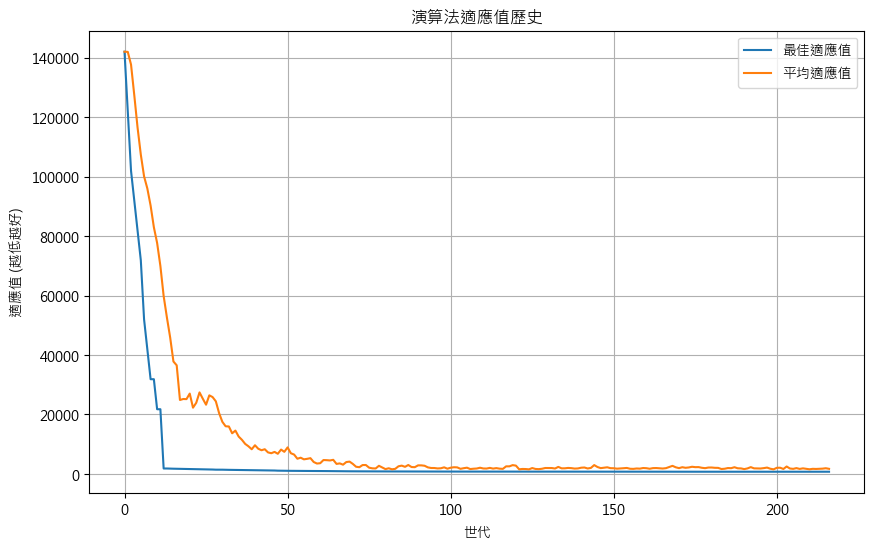


----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 0
C02：淘汰訂單數 = 0, 行駛距離 = 0
C03：淘汰訂單數 = 0, 行駛距離 = 0
C04：淘汰訂單數 = 0, 行駛距離 = 0
C05：淘汰訂單數 = 0, 行駛距離 = 42
C06：淘汰訂單數 = 0, 行駛距離 = 0
C07：淘汰訂單數 = 0, 行駛距離 = 0
C08：淘汰訂單數 = 0, 行駛距離 = 40
C09：淘汰訂單數 = 0, 行駛距離 = 0
C10：淘汰訂單數 = 0, 行駛距離 = 0
C11：淘汰訂單數 = 0, 行駛距離 = 0
C12：淘汰訂單數 = 0, 行駛距離 = 0
C13：淘汰訂單數 = 0, 行駛距離 = 0
C14：淘汰訂單數 = 0, 行駛距離 = 0
C15：淘汰訂單數 = 0, 行駛距離 = 79
C16：淘汰訂單數 = 0, 行駛距離 = 0
C17：淘汰訂單數 = 0, 行駛距離 = 0
C18：淘汰訂單數 = 0, 行駛距離 = 0
C19：淘汰訂單數 = 0, 行駛距離 = 53
C20：淘汰訂單數 = 0, 行駛距離 = 48
C21：淘汰訂單數 = 0, 行駛距離 = 0
C22：淘汰訂單數 = 0, 行駛距離 = 0
C23：淘汰訂單數 = 0, 行駛距離 = 46
C24：淘汰訂單數 = 0, 行駛距離 = 0
C25：淘汰訂單數 = 0, 行駛距離 = 0
C26：淘汰訂單數 = 0, 行駛距離 = 0
C27：淘汰訂單數 = 0, 行駛距離 = 25
C28：淘汰訂單數 = 0, 行駛距離 = 61
C29：淘汰訂單數 = 0, 行駛距離 = 0
C30：淘汰訂單數 = 0, 行駛距離 = 46
C31：淘汰訂單數 = 0, 行駛距離 = 40
C32：淘汰訂單數 = 0, 行駛距離 = 0
C33：淘汰訂單數 = 0, 行駛距離 = 0
C34：淘汰訂單數 = 0, 行駛距離 = 0
C35：淘汰訂單數 = 0, 行駛距離 = 0
C36：淘汰訂單數 = 0, 行駛距離 = 0
C37：淘汰訂單數 = 0, 行駛距離 = 65
C38：淘汰訂單數 = 0, 行駛距離 = 70
C39：淘汰訂單數 = 0, 行駛距離 = 53
C40：淘汰訂單數 = 0, 行駛距離 = 62

--

In [27]:
# 調整參數
scheduler.batch_capacity = 20

# 遺傳算法參數
scheduler.pop_size = 1000
scheduler.generations = 1000
scheduler.elite_size = 50
scheduler.mutation_rate = 0.4
scheduler.tournament_size = 10

scheduler.earlier_ga_stop = 50



# 修改適應值函數，納入時間因素
# scheduler.modify_fitness_function(include_time=True, time_weight=0.5)

# 執行混合算法
scheduler.run()

# 繪製演化歷史
scheduler.plot_history()

# 分析結果
metrics = scheduler.analyze_results()

# 保存結果到Excel
scheduler.save_results("optimized_schedule.xlsx")

# 查看最佳解的適應值
print(f"\n最佳解適應值: {scheduler.best_fit}")